In [1]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.3 MB/s eta 0:00:0000:01


2026-03-06 14:24:56.247773: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772807096.450960      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772807096.504030      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772807096.998645      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772807096.998690      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772807096.998692      55 computation_placer.cc:177] computation placer alr

Epoch 1/25


I0000 00:00:1772807246.094166     151 service.cc:152] XLA service 0x7b4310001970 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772807246.094202     151 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1772807246.094208     151 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1772807247.785876     151 cuda_dnn.cc:529] Loaded cuDNN version 91002


  3/114 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.6146 - loss: 0.7747 

I0000 00:00:1772807261.460020     151 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


114/114 ━━━━━━━━━━━━━━━━━━━━ 46s 194ms/step - accuracy: 0.7772 - loss: 0.5317 - val_accuracy: 0.8729 - val_loss: 0.2767
Epoch 2/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.8771 - loss: 0.3061 - val_accuracy: 0.8950 - val_loss: 0.2334
Epoch 3/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9021 - loss: 0.2642 - val_accuracy: 0.9274 - val_loss: 0.2088
Epoch 4/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9264 - loss: 0.2231 - val_accuracy: 0.9416 - val_loss: 0.1862
Epoch 5/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9448 - loss: 0.1807 - val_accuracy: 0.9479 - val_loss: 0.1469
Epoch 6/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9479 - loss: 0.1676 - val_accuracy: 0.9542 - val_loss: 0.1382
Epoch 7/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9477 - loss: 0.1598 - val_accuracy: 0.9597 - val_loss: 0.1189
Epoch 8/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.9600 - loss: 0.1272 - val_accuracy: 0.9

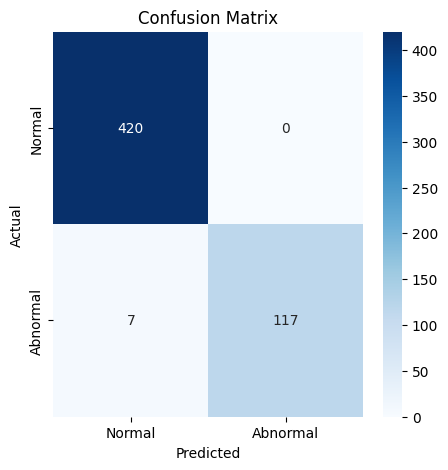

Model: "Hybrid_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ECG_Input           │ (None, 200, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ PCG_Input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_mamba_model     │ (None, 128)       │    265,216 │ ECG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pcg_transformer     │ (None, 256)       │  2,433,280 │ PCG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 384)       │          0 │ ecg_mamba_model[… │
│ (Concatenate)       │                   │            │ pcg_transformer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 256)       │     98,560 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_mamba_b… │ (None, 256)       │    263,424 │ dense_10[0][0]    │
│ (MultimodalMambaBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_mamba_b… │ (None, 256)       │    263,424 │ multimodal_mamba… │
│ (MultimodalMambaBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 2)         │        514 │ multimodal_mamba… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,973,256 (38.04 MB)

 Trainable params: 3,324,418 (12.68 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,648,838 (25.36 MB)

In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from imblearn.over_sampling import SMOTE
from scipy.io import wavfile
from scipy.signal import stft
import wfdb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- ECG Mamba Model Implementation (from ECGMamba paper) ---
# This is a minimal, self-contained Mamba block for 1D ECG data, inspired by the paper.
# If you have the official Mamba library, you can use it directly. Otherwise, this is a simplified version.

class SimpleMambaBlock(layers.Layer):
    def __init__(self, d_model, ssm_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.ssm_dim = ssm_dim
        self.dropout = dropout
        self.dense1 = layers.Dense(ssm_dim, activation='gelu')
        self.dense2 = layers.Dense(d_model)
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        # SSM-like block: project, nonlinearity, project back, residual
        h = self.dense1(x)
        h = self.drop(h, training=training)
        h = self.dense2(h)
        h = self.drop(h, training=training)
        return self.norm(x + h)

# ECG Mamba Model

def ecg_mamba_model(input_shape, d_model=128, ssm_dim=256, num_blocks=4, dropout=0.1):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(d_model, kernel_size=3, padding='same', activation='gelu')(inputs)
    for _ in range(num_blocks):
        x = SimpleMambaBlock(d_model, ssm_dim, dropout)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="ecg_mamba_model")

# Multimodal Mamba Fusion Block
class MultimodalMambaBlock(layers.Layer):
    def __init__(self, d_model, ssm_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.ssm_dim = ssm_dim
        self.dropout = dropout
        self.dense1 = layers.Dense(ssm_dim, activation='gelu')
        self.dense2 = layers.Dense(d_model)
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        h = self.dense1(x)
        h = self.drop(h, training=training)
        h = self.dense2(h)
        h = self.drop(h, training=training)
        return self.norm(x + h)

# Multimodal Mamba Fusion Model

def multimodal_mamba_fusion(ecg_output, pcg_output, d_model=256, ssm_dim=512, num_blocks=2, dropout=0.1):
    combined = layers.Concatenate()([ecg_output, pcg_output])
    x = layers.Dense(d_model, activation='gelu')(combined)
    for _ in range(num_blocks):
        x = MultimodalMambaBlock(d_model, ssm_dim, dropout)(x)
    return x

# Constants
IMG_HEIGHT = 128
IMG_WIDTH = 128
PATCH_SIZE = 16
EMBED_DIM = 256
NUM_HEADS = 8
FF_DIM = 512
DROPOUT_RATE = 0.3
NUM_CLASSES = 2
INPUT_ECG_SHAPE = (200, 1)
INPUT_PCG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 1)
BATCH_SIZE = 64
EPOCHS = 25
LEARNING_RATE = 1e-5

# Helper function to compute PCG spectrogram
def compute_spectrogram(filepath):
    sample_rate, signal = wavfile.read(filepath)
    frequencies, times, spectrogram = stft(signal, fs=sample_rate, nperseg=256)
    spectrogram = np.log(np.abs(spectrogram) + 1e-10)
    spectrogram = np.resize(spectrogram, (IMG_HEIGHT, IMG_WIDTH))
    return spectrogram

# Load PCG dataset with augmentation for abnormal cases
def load_pcg_dataset(normal_dir, abnormal_dir):
    data, labels = [], []
    for label, directory in enumerate([normal_dir, abnormal_dir]):
        for filename in os.listdir(directory):
            if filename.endswith(".wav"):
                filepath = os.path.join(directory, filename)
                spectrogram = compute_spectrogram(filepath)
                data.append(spectrogram)
                labels.append(label)
                # Augment abnormal data by flipping
                if label == 1:
                    flipped_spectrogram = np.flip(spectrogram, axis=1)
                    data.append(flipped_spectrogram)
                    labels.append(label)
    return np.array(data), np.array(labels)

# Load ECG dataset
def load_clean_ecg_data(data_path):
    records = [f.split('.')[0] for f in os.listdir(data_path) if f.endswith('.dat')]
    X, Y = [], []
    for record in records:
        signal, fields = wfdb.rdsamp(os.path.join(data_path, record))
        ann = wfdb.rdann(os.path.join(data_path, record), 'atr')
        for i in range(len(ann.sample)):
            if i == 0 or i == len(ann.sample) - 1:
                continue
            r_peak = ann.sample[i]
            start = r_peak - 100
            end = r_peak + 100
            if start < 0 or end > len(signal):
                continue
            heartbeat = signal[start:end, 0]
            X.append(heartbeat)
            Y.append(ann.symbol[i])
    return np.array(X), np.array(Y)

# Map ECG labels to binary classes
def label_ecg(y):
    normal_classes = ['N', 'L', 'R']
    return 0 if y in normal_classes else 1

# Data paths
pcg_normal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor/combined_heart_sound_data(physionet +circor)/Normal"
pcg_abnormal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor/combined_heart_sound_data(physionet +circor)/Abnormal"
ecq_data_path = "/kaggle/input/datasets/mahirazmainhaque/ecg-notebook-data/mit-bih-arrhythmia-database-1.0.0/mit-bih-arrhythmia-database-1.0.0"

# Load and preprocess PCG data
pcg_data, pcg_labels = load_pcg_dataset(pcg_normal_dir, pcg_abnormal_dir)
pcg_data = pcg_data / np.max(pcg_data)
pcg_data = np.expand_dims(pcg_data, -1)
pcg_labels = tf.keras.utils.to_categorical(pcg_labels, NUM_CLASSES)

# Load and preprocess ECG data
X_clean, Y_clean = load_clean_ecg_data(ecq_data_path)
scaler = StandardScaler()
X_clean = np.array([scaler.fit_transform(x.reshape(-1, 1)).flatten() for x in X_clean])
Y_clean = np.array([label_ecg(y) for y in Y_clean])

# Apply SMOTE to balance ECG dataset
smote = SMOTE(random_state=42)
X_clean, Y_clean = smote.fit_resample(X_clean, Y_clean)
Y_clean = tf.keras.utils.to_categorical(Y_clean, NUM_CLASSES)
X_clean = X_clean[..., np.newaxis]

# Balance datasets
min_samples = min(len(X_clean), len(pcg_data))
X_clean, Y_clean = shuffle(X_clean[:min_samples], Y_clean[:min_samples], random_state=42)
pcg_data, pcg_labels = shuffle(pcg_data[:min_samples], pcg_labels[:min_samples], random_state=42)

# Train-test split
x_train_pcg, x_test_pcg, y_train_pcg, y_test_pcg = train_test_split(pcg_data, pcg_labels, test_size=0.2, random_state=42)
x_val_pcg, x_test_pcg, y_val_pcg, y_test_pcg = train_test_split(x_test_pcg, y_test_pcg, test_size=0.3, random_state=42)

x_train_ecg, x_test_ecg, y_train_ecg, y_test_ecg = train_test_split(X_clean, Y_clean, test_size=0.2, random_state=42)
x_val_ecg, x_test_ecg, y_val_ecg, y_test_ecg = train_test_split(x_test_ecg, y_test_ecg, test_size=0.3, random_state=42)
# Patch Embedding Layer for PCG
def patch_embedding(input_shape, patch_size, embed_dim):
    inputs = layers.Input(shape=input_shape)
    patches = layers.Conv2D(embed_dim, (patch_size, patch_size), strides=(patch_size, patch_size))(inputs)
    flat_patches = layers.Reshape((-1, embed_dim))(patches)
    return models.Model(inputs, flat_patches, name="patch_embedding")

# Transformer Block
def transformer_block(embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=(None, embed_dim))
    attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)(inputs, inputs)
    attention_output = layers.Dropout(dropout_rate)(attention_output)
    attention_output = layers.LayerNormalization(epsilon=1e-6)(inputs + attention_output)

    ffn_output = layers.Dense(ff_dim, activation='relu')(attention_output)
    ffn_output = layers.Dense(embed_dim)(ffn_output)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    outputs = layers.LayerNormalization(epsilon=1e-6)(attention_output + ffn_output)

    return models.Model(inputs, outputs, name="transformer_block")

# PCG Transformer Model
def pcg_transformer(input_shape, patch_size, embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=input_shape)
    x = patch_embedding(input_shape, patch_size, embed_dim)(inputs)
    x = transformer_block(embed_dim, num_heads, ff_dim, dropout_rate)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="pcg_transformer")

# Final Hybrid Model
def hybrid_transformer_model():
    ecg_input = layers.Input(shape=INPUT_ECG_SHAPE, name="ECG_Input")
    pcg_input = layers.Input(shape=INPUT_PCG_SHAPE, name="PCG_Input")

    # Use ECG Mamba model instead of transformer
    ecg_model = ecg_mamba_model(INPUT_ECG_SHAPE, d_model=128, ssm_dim=256, num_blocks=4, dropout=0.1)
    pcg_model = pcg_transformer(INPUT_PCG_SHAPE, PATCH_SIZE, EMBED_DIM, NUM_HEADS, FF_DIM, DROPOUT_RATE)

    ecg_output = ecg_model(ecg_input)
    pcg_output = pcg_model(pcg_input)

    # Use Multimodal Mamba Fusion only
    fusion_output = multimodal_mamba_fusion(ecg_output, pcg_output, d_model=EMBED_DIM, ssm_dim=512, num_blocks=2, dropout=DROPOUT_RATE)

    # Remove Stacked Transformer Ensemble
    # Combine Fusion Output directly
    outputs = layers.Dense(NUM_CLASSES, activation='sigmoid')(fusion_output)

    model = models.Model(inputs=[ecg_input, pcg_input], outputs=outputs, name="Hybrid_Transformer")
    model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss=losses.BinaryCrossentropy(),
                  metrics=['accuracy'])

    return model

model = hybrid_transformer_model()
history = model.fit(
    [x_train_ecg, x_train_pcg], y_train_ecg,
    validation_data=([x_val_ecg, x_val_pcg], y_val_ecg),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)
y_pred_prob = model.predict([x_test_ecg, x_test_pcg])
y_pred = (y_pred_prob[:, 1] > 0.4).astype(int)  # Adjusted threshold for better recall
y_true = np.argmax(y_test_ecg, axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred))
print("AUC-ROC:", roc_auc_score(y_true, y_pred_prob[:, 1]))

plt.figure(figsize=(5, 5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Abnormal'], yticklabels=['Normal', 'Abnormal'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

model.summary()


In [5]:
# Evaluate model on test set
test_loss, test_accuracy = model.evaluate([x_test_ecg, x_test_pcg], y_test_ecg, batch_size=BATCH_SIZE)
print(f"Test Accuracy: {test_accuracy:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 211ms/step - accuracy: 0.9900 - loss: 0.0507
Test Accuracy: 0.9835


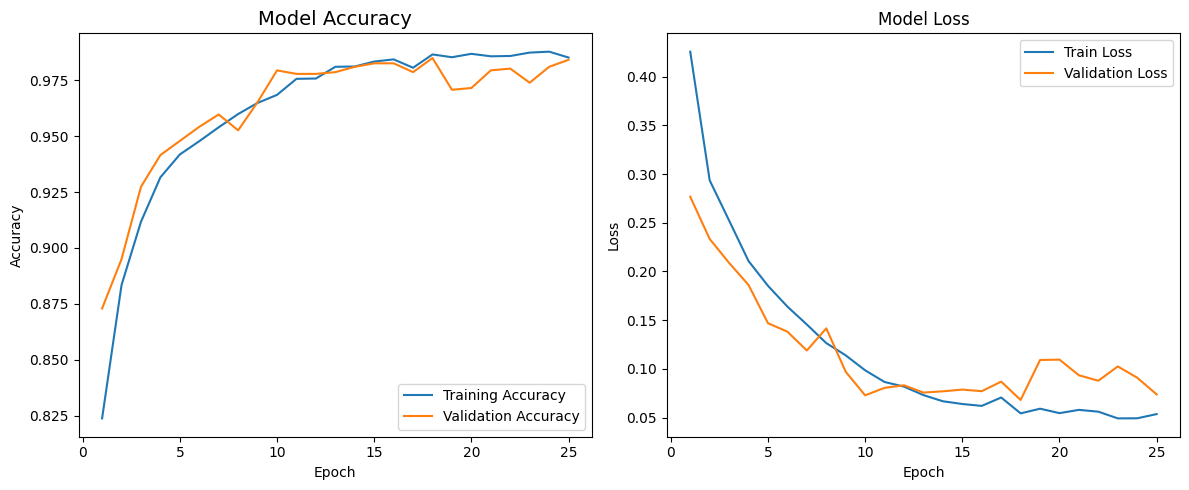

In [3]:
import matplotlib.pyplot as plt

# Extract data from history
train_accuracy = history.history.get('accuracy', [])
val_accuracy = history.history.get('val_accuracy', [])
train_loss = history.history.get('loss', [])
val_loss = history.history.get('val_loss', [])

epochs = range(1, len(train_accuracy) + 1)

# Plotting model accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plotting model loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Train Loss')  # Updated training color
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
# Set DPI to 300
plt.tight_layout()
plt.savefig('Hybrid_model.png', dpi=300)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       420
           1       1.00      0.93      0.96       124

    accuracy                           0.98       544
   macro avg       0.99      0.96      0.98       544
weighted avg       0.98      0.98      0.98       544



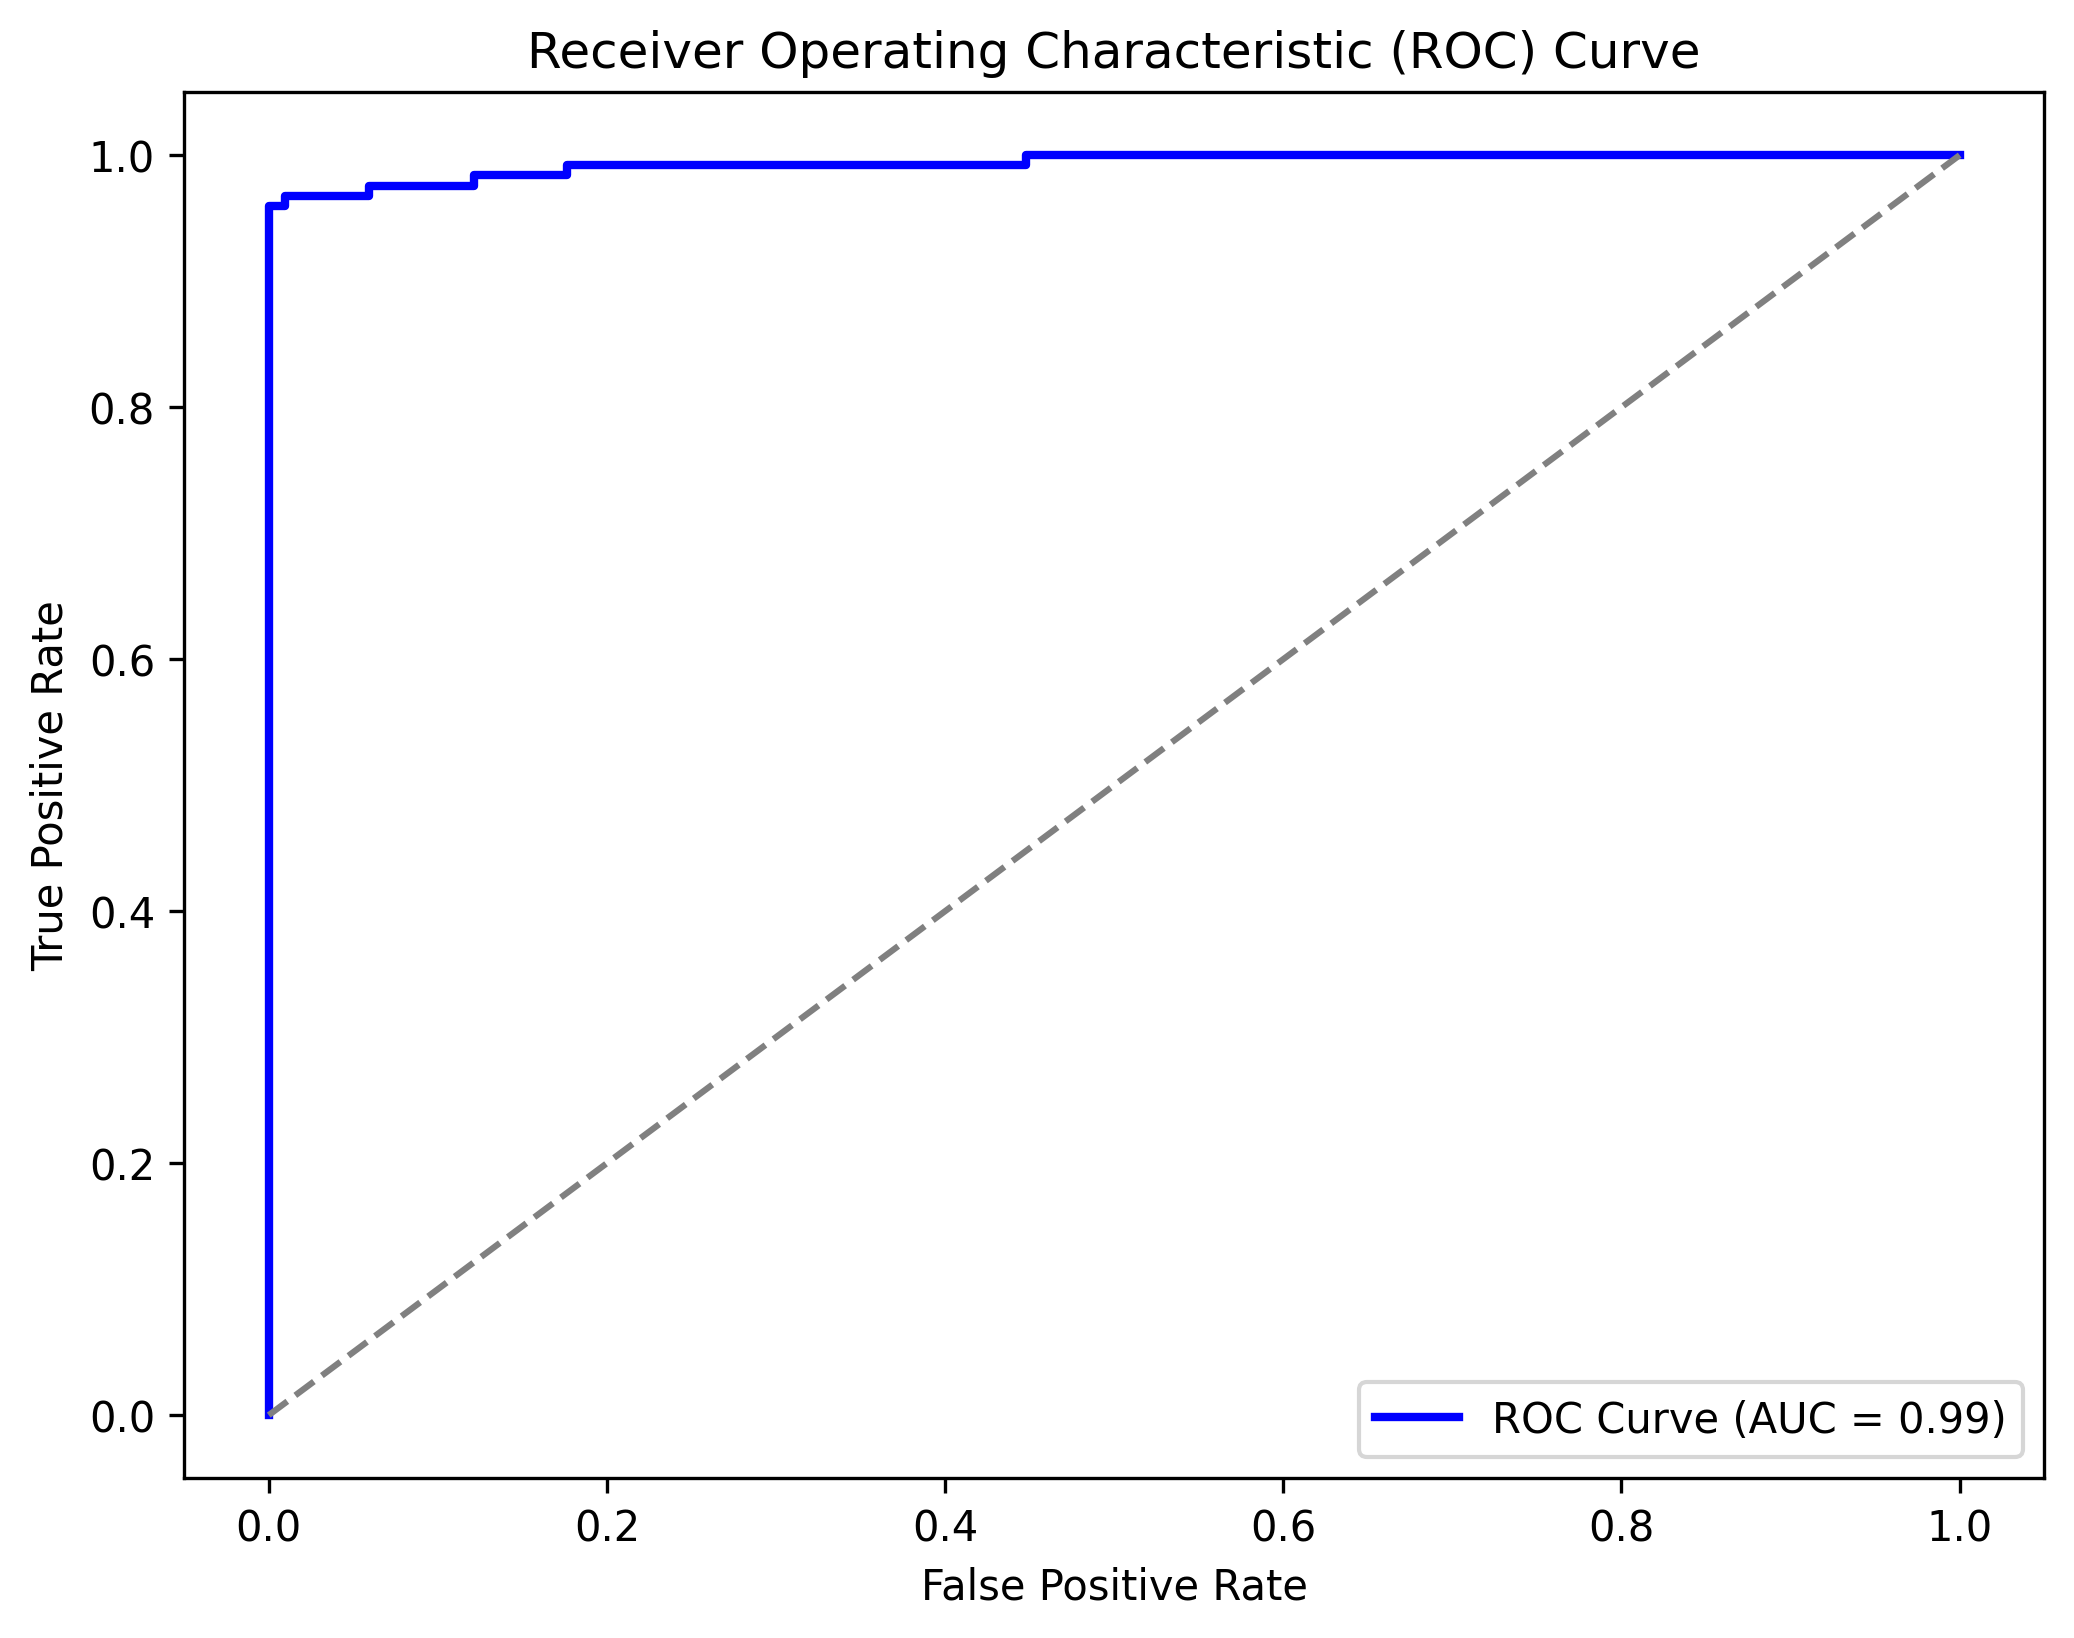

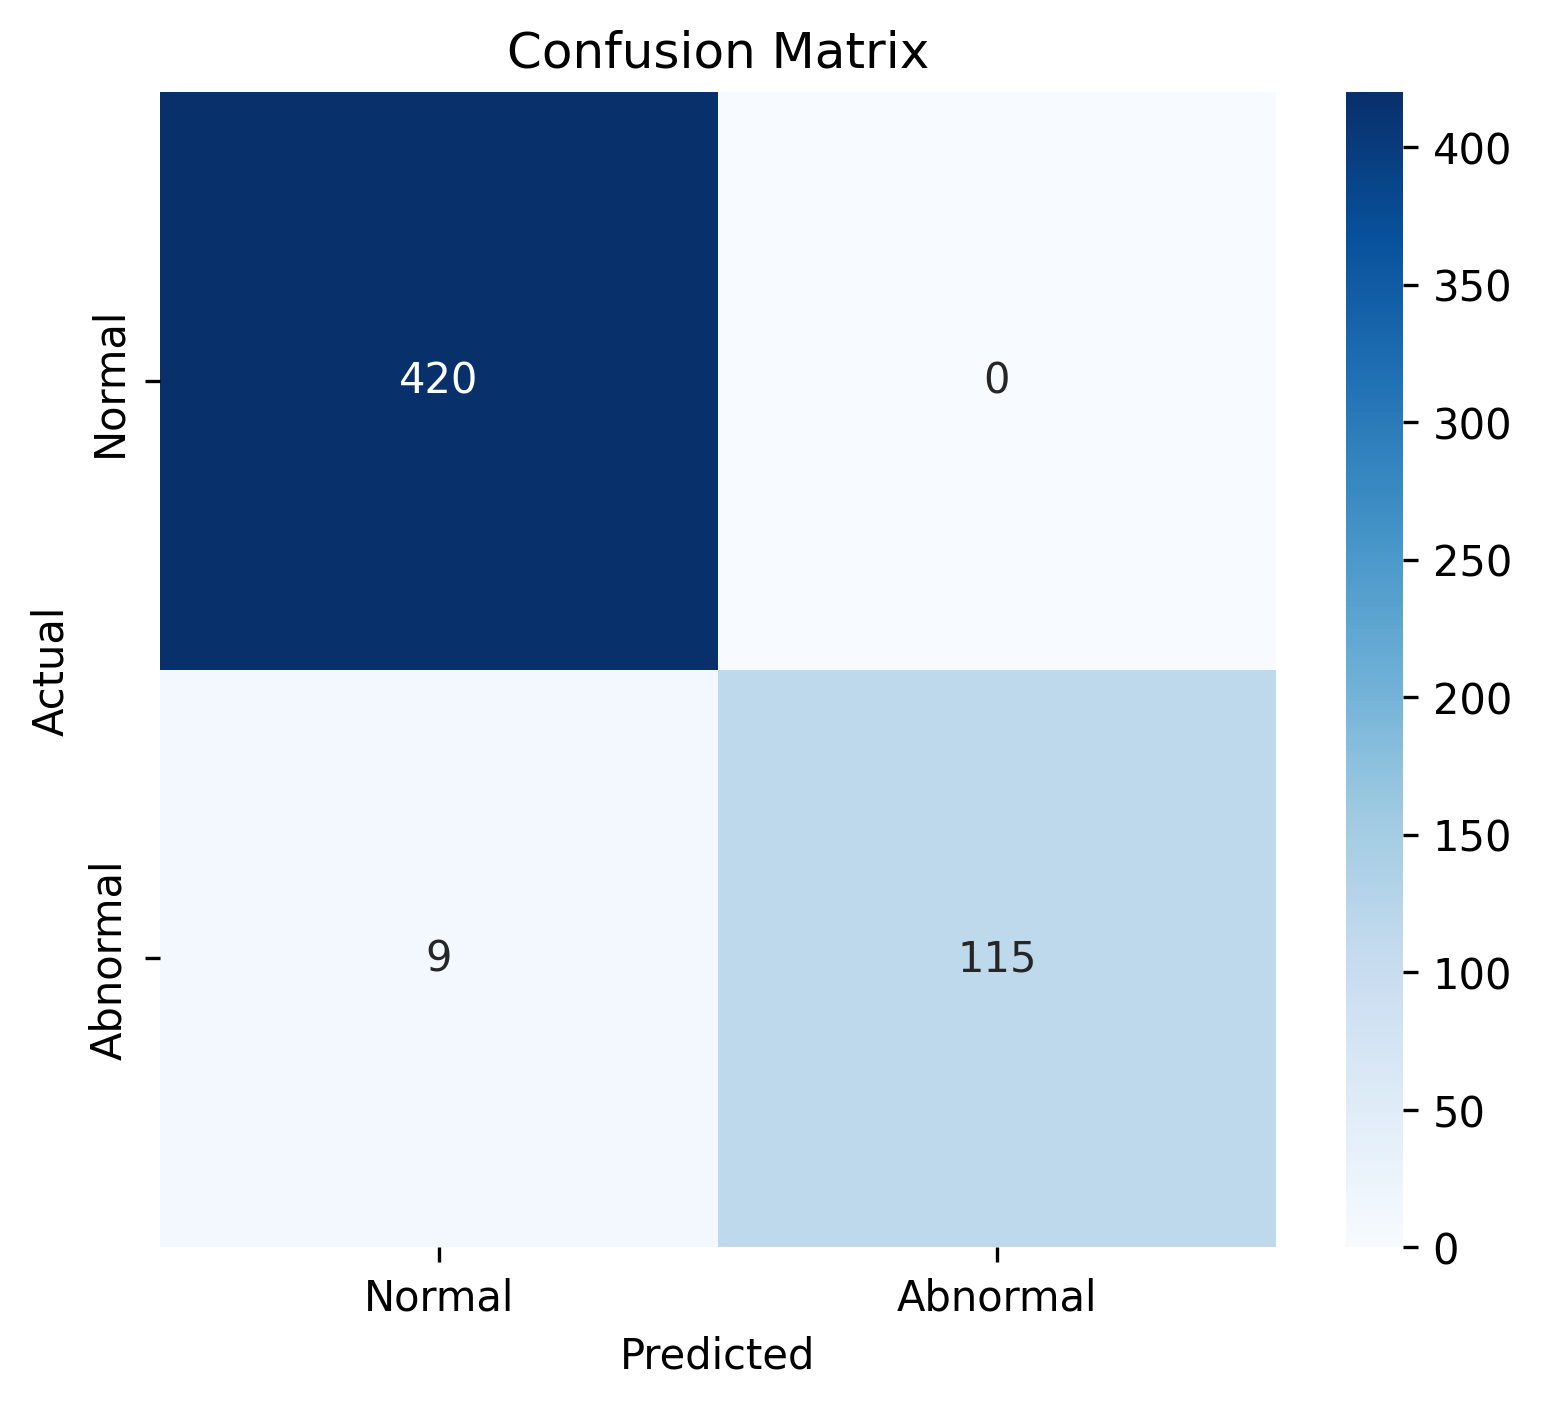

In [4]:
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_pred_probs = model.predict([x_test_ecg, x_test_pcg])  # Probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Convert to class labels
y_true = np.argmax(y_test_ecg, axis=1)  # True labels (assuming same for ECG & PCG)

# Compute ROC AUC Score
fpr, tpr, _ = roc_curve(y_true, y_pred_probs[:, 1])
roc_auc = auc(fpr, tpr)

# Generate Classification Report
class_report = classification_report(y_true, y_pred_classes)
print("Classification Report:\n", class_report)

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot ROC Curve
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig("roc_curve.png", dpi=300)  # Save at 300 dpi
plt.show()

# Plot Confusion Matrix
plt.figure(figsize=(6, 5), dpi=300)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300)  # Save at 300 dpi
plt.show()


In [5]:
# Save the trained model to a file
model.save('/kaggle/working/Multimodal_Mamba_Hybrid_Model1.keras')
print("Model saved as 'Multimodal_Mamba_Hybrid_Model.keras'")


Model saved as 'Multimodal_Mamba_Hybrid_Model.keras'
